# 비지도 학습
## [1] 차원축소

### 실제 라벨 기준 군집별 데이터 개수 확인

In [ ]:
import pandas as pd

# iris.csv 파일 로드 (경로는 환경에 맞게 조정 가능합니다)
try:
    df = pd.read_csv('iris.csv')
except FileNotFoundError:
    # 만약 현재 경로에 없다면 seaborn을 통해 기본 제공되는 데이터를 로드해 사용합니다.
    import seaborn as sns
    df = sns.load_dataset('iris')

# 데이터프레임 출력
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),label
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


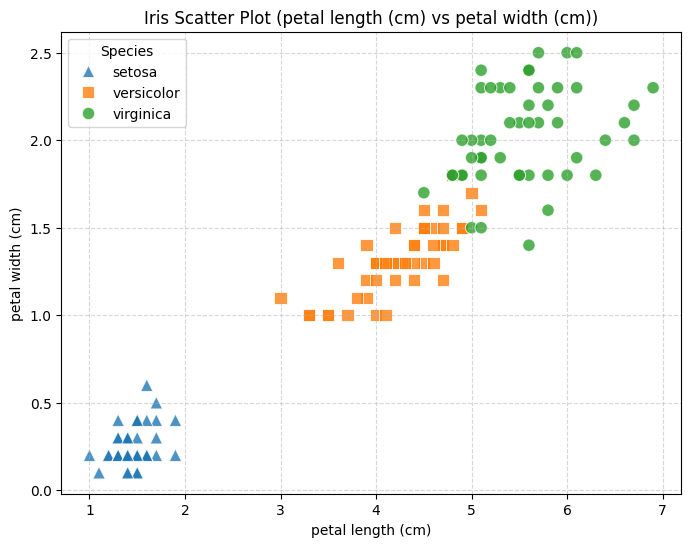

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 3번째(인덱스 2), 4번째(인덱스 3) 컬럼 가져오기
x_col = df.columns[2]
y_col = df.columns[3]
label_col = df.columns[-1]

# 라벨이 숫자인 경우 문자열 품종명으로 매핑
label_map = {0: 'setosa', 1: 'versicolor', 2: 'virginica'}
plot_df = df.copy()
if plot_df[label_col].dtype in ['int64', 'int32', 'float64']:
    plot_df['species'] = plot_df[label_col].map(label_map)
else:
    plot_df['species'] = plot_df[label_col]

# 마커 매핑 정의 (setosa: 세모 '^', versicolor: 네모 's', virginica: 동그라미 'o')
markers = {'setosa': '^', 'versicolor': 's', 'virginica': 'o'}

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=plot_df,
    x=x_col,
    y=y_col,
    hue='species',
    style='species',
    markers=markers,
    s=80,
    alpha=0.8
)

plt.title(f'Iris Scatter Plot ({x_col} vs {y_col})')
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.legend(title='Species')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

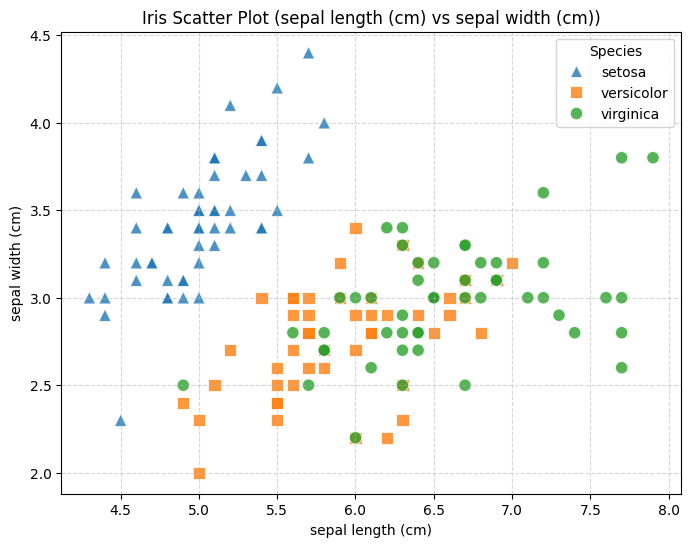

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 컬럼명 가져오기
x_col = df.columns[0]
y_col = df.columns[1]
label_col = df.columns[-1]

# 라벨이 숫자인 경우 문자열 품종명으로 매핑
label_map = {0: 'setosa', 1: 'versicolor', 2: 'virginica'}
plot_df = df.copy()
if plot_df[label_col].dtype in ['int64', 'int32', 'float64']:
    plot_df['species'] = plot_df[label_col].map(label_map)
else:
    plot_df['species'] = plot_df[label_col]

# 마커 매핑 정의 (setosa: 세모 '^', versicolor: 네모 's', virginica: 동그라미 'o')
markers = {'setosa': '^', 'versicolor': 's', 'virginica': 'o'}

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=plot_df,
    x=x_col,
    y=y_col,
    hue='species',
    style='species',
    markers=markers,
    s=80,
    alpha=0.8
)

plt.title(f'Iris Scatter Plot ({x_col} vs {y_col})')
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.legend(title='Species')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 4개 피처(0~3번째 컬럼) 추출
X = df.iloc[:, :4]

# PCA 적용 전 데이터 표준화(스케일링)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2개 주성분으로 PCA 차원 축소
pca = PCA(n_components=2)
pca_transformed = pca.fit_transform(X_scaled)

# 차원 축소된 결과를 데이터프레임으로 변환
pca_df = pd.DataFrame(pca_transformed, columns=['pca_1', 'pca_2'])

# 원본 데이터의 라벨 추가
pca_df['label'] = df[df.columns[-1]].values

# 설명된 분산 비율 출력
print(f"설명된 분산 비율(Explained variance ratio): {pca.explained_variance_ratio_}")
print(f"총 설명 분산(합계): {pca.explained_variance_ratio_.sum():.4f}")

# 테이블 출력
display(pca_df.head())

설명된 분산 비율(Explained variance ratio): [0.72962445 0.22850762]
총 설명 분산(합계): 0.9581


,pca_1,pca_2,label
0,-2.264703,0.480027,0
1,-2.080961,-0.674134,0
2,-2.364229,-0.341908,0
3,-2.299384,-0.597395,0
4,-2.389842,0.646835,0


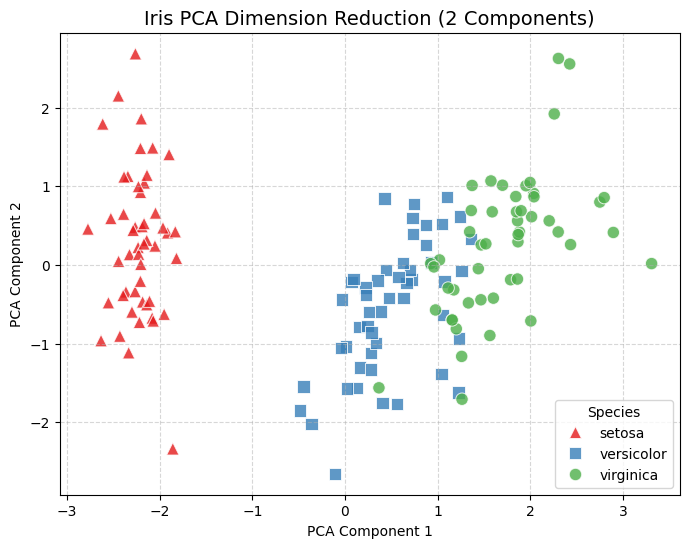

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 라벨 매핑 (0: setosa, 1: versicolor, 2: virginica)
label_map = {0: 'setosa', 1: 'versicolor', 2: 'virginica'}
plot_pca_df = pca_df.copy()

if plot_pca_df['label'].dtype in ['int64', 'int32', 'float64']:
    plot_pca_df['species'] = plot_pca_df['label'].map(label_map)
else:
    plot_pca_df['species'] = plot_pca_df['label']

# 마커 매핑
markers = {'setosa': '^', 'versicolor': 's', 'virginica': 'o'}

# 산점도 시각화
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=plot_pca_df,
    x='pca_1',
    y='pca_2',
    hue='species',
    style='species',
    markers=markers,
    palette='Set1',
    s=80,
    alpha=0.8
)

plt.title('Iris PCA Dimension Reduction (2 Components)', fontsize=14)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Species')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## [2] 군집화(Clustering)

=== 각 군집(Cluster)별 중심점 좌표 (원본 피처 기준) ===


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
cluster,,,,
0,5.901613,2.748387,4.393548,1.433871
1,5.006000,3.428000,1.462000,0.246000
2,6.850000,3.073684,5.742105,2.071053



=== 각 데이터 및 속한 군집 중심점 (상위 5개 행) ===


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),cluster,center_sepal length (cm),center_sepal width (cm),center_petal length (cm),center_petal width (cm)
0,5.1,3.5,1.4,0.2,1,5.006,3.428,1.462,0.246
1,4.9,3.0,1.4,0.2,1,5.006,3.428,1.462,0.246
2,4.7,3.2,1.3,0.2,1,5.006,3.428,1.462,0.246
3,4.6,3.1,1.5,0.2,1,5.006,3.428,1.462,0.246
4,5.0,3.6,1.4,0.2,1,5.006,3.428,1.462,0.246


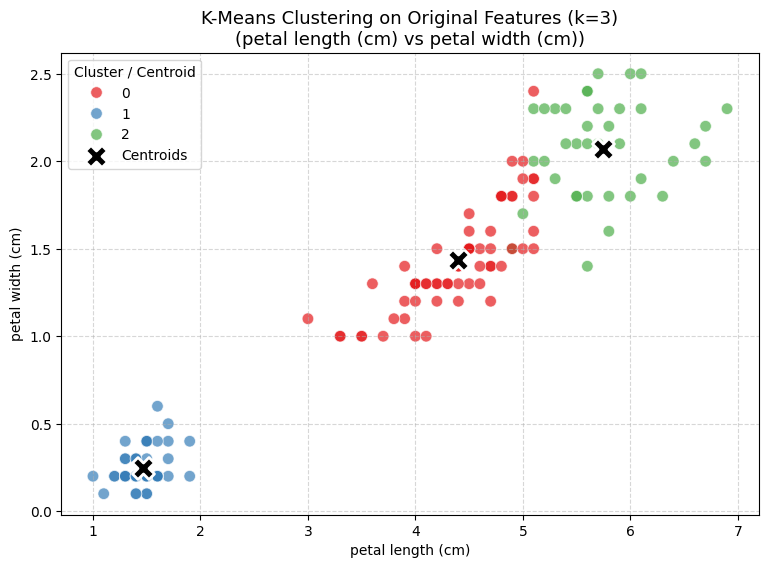

In [ ]:
from sklearn.cluster import KMeans
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 원본 4개 피처 데이터 준비 (차원축소 미적용)
feature_cols = df.columns[:4].tolist()
X_orig = df[feature_cols]

# 2. KMeans 군집화 (k=3)
kmeans_orig = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans_orig.fit_predict(X_orig)

# 3. 군집 중심점 (원본 4차원 공간)
centers_orig = kmeans_orig.cluster_centers_
centers_df = pd.DataFrame(centers_orig, columns=feature_cols)
centers_df.index.name = 'cluster'

print("=== 각 군집(Cluster)별 중심점 좌표 (원본 피처 기준) ===")
display(centers_df)

# 4. 각 데이터에 할당된 군집 및 해당 군집의 중심점 좌표 매핑
result_df = X_orig.copy()
result_df['cluster'] = cluster_labels
for col in feature_cols:
    result_df[f'center_{col}'] = result_df['cluster'].map(centers_df[col])

print("\n=== 각 데이터 및 속한 군집 중심점 (상위 5개 행) ===")
display(result_df.head())

# 5. 군집 결과 및 중심점 시각화 (구분력이 가장 높은 Petal 컬럼 기준)
x_col, y_col = feature_cols[2], feature_cols[3]

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=result_df,
    x=x_col,
    y=y_col,
    hue='cluster',
    palette='Set1',
    s=70,
    alpha=0.7,
    legend='full'
)

# 각 군집의 중심점 표시 (X 마커)
plt.scatter(
    centers_df[x_col],
    centers_df[y_col],
    c='black',
    s=250,
    marker='X',
    edgecolors='white',
    linewidth=2,
    label='Centroids'
)

plt.title(f'K-Means Clustering on Original Features (k=3)\n({x_col} vs {y_col})', fontsize=13)
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.legend(title='Cluster / Centroid')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [10]:
import pandas as pd

# 실제 라벨명 매핑 정보 정의
label_map = {0: 'setosa', 1: 'versicolor', 2: 'virginica'}

# 데이터프레임 생성
summary_df = pd.DataFrame({
    'Actual_Label': df[df.columns[-1]].map(label_map) if df[df.columns[-1]].dtype in ['int64', 'int32', 'float64'] else df[df.columns[-1]],
    'Cluster': cluster_labels
})

# crosstab을 사용하여 실제 라벨 기준 군집에 속한 개수 테이블 생성
cluster_table = pd.crosstab(index=summary_df['Actual_Label'], columns=summary_df['Cluster'], margins=True, margins_name='Total')

display(cluster_table)

Cluster,0,1,2,Total
Actual_Label,,,,
setosa,0,50,0,50
versicolor,48,0,2,50
virginica,14,0,36,50
Total,62,50,38,150


### 군집 개수(k)별 실루엣 계수 비교

,Number of Clusters (k),Silhouette Coefficient
0,2,0.681046
1,3,0.552819
2,4,0.498051
3,5,0.491240
4,6,0.364834


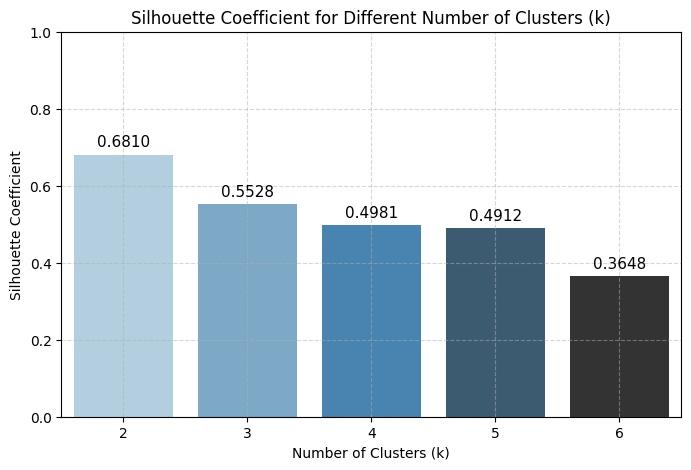

In [11]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 원본 4개 피처 데이터 사용
feature_cols = df.columns[:4].tolist()
X_orig = df[feature_cols]

# 2. k값 리스트 및 실루엣 점수를 저장할 딕셔너리 정의
k_values = [2, 3, 4, 5, 6]
silhouette_scores = {}

# 3. 각 k에 대해 군집화 수행 후 실루엣 계수 계산
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_orig)
    score = silhouette_score(X_orig, labels)
    silhouette_scores[k] = score

# 4. 결과를 데이터프레임으로 변환하여 출력
results_df = pd.DataFrame(list(silhouette_scores.items()), columns=['Number of Clusters (k)', 'Silhouette Coefficient'])
display(results_df)

# 5. 시각화
plt.figure(figsize=(8, 5))
sns.barplot(x='Number of Clusters (k)', y='Silhouette Coefficient', data=results_df, palette='Blues_d', hue='Number of Clusters (k)', legend=False)
plt.title('Silhouette Coefficient for Different Number of Clusters (k)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Coefficient')
plt.grid(True, linestyle='--', alpha=0.5)
plt.ylim(0, 1) # 실루엣 계수 범위

# 각 막대 위에 값 표시
for idx, row in results_df.iterrows():
    plt.text(idx, row['Silhouette Coefficient'] + 0.02, f"{row['Silhouette Coefficient']:.4f}", ha='center', fontsize=11)

plt.show()